In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [9]:
data = {'R&D' : [165, 101, 29], 'Ops': [137, 92, 127], 'Marketing' : [472, 250, 201], 'profit' : [192, 144, 91]}

In [10]:
df = pd.DataFrame(data)

In [11]:
df

,R&D,Ops,Marketing,profit
0,165,137,472,192
1,101,92,250,144
2,29,127,201,91


In [12]:
df['f0(x)'] = df['profit'].mean()

In [13]:
df

,R&D,Ops,Marketing,profit,f0(x)
0,165,137,472,192,142.333333
1,101,92,250,144,142.333333
2,29,127,201,91,142.333333


In [15]:
df['r1'] = df['profit'] - df['f0(x)']

In [16]:
df

,R&D,Ops,Marketing,profit,f0(x),r1
0,165,137,472,192,142.333333,49.666667
1,101,92,250,144,142.333333,1.666667
2,29,127,201,91,142.333333,-51.333333


In [20]:
from sklearn.tree import DecisionTreeRegressor, plot_tree

In [21]:
dt1 = DecisionTreeRegressor(max_depth= 2)

In [23]:
dt1.fit(df.iloc[:, :3], df.iloc[:, -1])

,criterion,'squared_error'
,splitter,'best'
,max_depth,2
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [24]:
df['f1(x)'] = df['f0(x)'] + dt1.predict(df.iloc[:, :3])

In [25]:
df

,R&D,Ops,Marketing,profit,f0(x),r1,f1(x)
0,165,137,472,192,142.333333,49.666667,192.0
1,101,92,250,144,142.333333,1.666667,144.0
2,29,127,201,91,142.333333,-51.333333,91.0


In [26]:
df['r2'] = df['profit'] - df['f1(x)']

In [27]:
df

,R&D,Ops,Marketing,profit,f0(x),r1,f1(x),r2
0,165,137,472,192,142.333333,49.666667,192.0,0.0
1,101,92,250,144,142.333333,1.666667,144.0,0.0
2,29,127,201,91,142.333333,-51.333333,91.0,0.0


In [28]:
dt2 = DecisionTreeRegressor(max_depth= 2)

In [29]:
dt2.fit(df.iloc[:, :3], df.iloc[:, -1])

,criterion,'squared_error'
,splitter,'best'
,max_depth,2
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [30]:
df['f2(x)'] = df['f1(x)'] + dt2.predict(df.iloc[:, :3])

In [31]:
df

,R&D,Ops,Marketing,profit,f0(x),r1,f1(x),r2,f2(x)
0,165,137,472,192,142.333333,49.666667,192.0,0.0,192.0
1,101,92,250,144,142.333333,1.666667,144.0,0.0,144.0
2,29,127,201,91,142.333333,-51.333333,91.0,0.0,91.0


In [39]:
np.random.seed(42)
X = np.random.rand(100, 1) - 0.5
y = 3 * X[:, 0]**2 + 0.05 * np.random.randn(100)

In [40]:
df = pd.DataFrame()

In [41]:
df['X'] = X.reshape(100)

In [42]:
df['y'] = y

In [43]:
df.head()

,X,y
0,-0.125460,0.051573
1,0.450714,0.594480
2,0.231994,0.166052
3,0.098658,-0.070178
4,-0.343981,0.343986


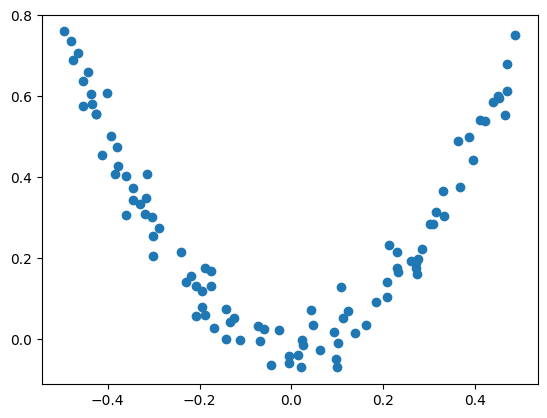

In [44]:
plt.scatter(df['X'], df['y'])

In [45]:
df['pred0'] = df['y'].mean()

In [46]:
df.head()

,X,y,pred0
0,-0.125460,0.051573,0.265458
1,0.450714,0.594480,0.265458
2,0.231994,0.166052,0.265458
3,0.098658,-0.070178,0.265458
4,-0.343981,0.343986,0.265458


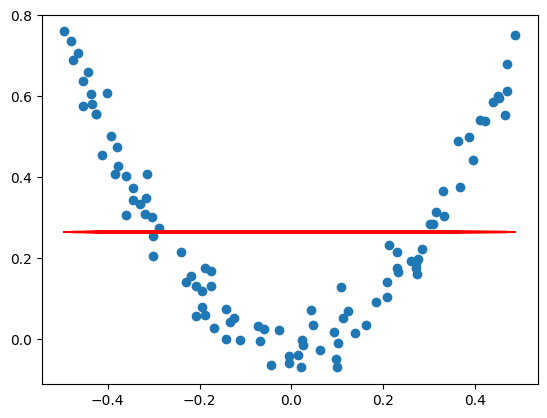

In [62]:
plt.scatter(df['X'], df['y'])
plt.plot(df['X'], df['pred0'], color = 'r')

In [47]:
df['r1'] = df['y'] - df['pred0']

In [48]:
df.head()

,X,y,pred0,r1
0,-0.125460,0.051573,0.265458,-0.213885
1,0.450714,0.594480,0.265458,0.329021
2,0.231994,0.166052,0.265458,-0.099407
3,0.098658,-0.070178,0.265458,-0.335636
4,-0.343981,0.343986,0.265458,0.078528


In [49]:
dt1 = DecisionTreeRegressor(max_depth= 3)

In [52]:
dt1.fit(X, df.iloc[:, -1])

,criterion,'squared_error'
,splitter,'best'
,max_depth,3
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [53]:
df['pred1'] = df['pred0'] + dt1.predict(X)

In [54]:
df.head()

,X,y,pred0,r1,pred1
0,-0.125460,0.051573,0.265458,-0.213885,0.083770
1,0.450714,0.594480,0.265458,0.329021,0.605884
2,0.231994,0.166052,0.265458,-0.099407,0.083770
3,0.098658,-0.070178,0.265458,-0.335636,0.083770
4,-0.343981,0.343986,0.265458,0.078528,0.305965


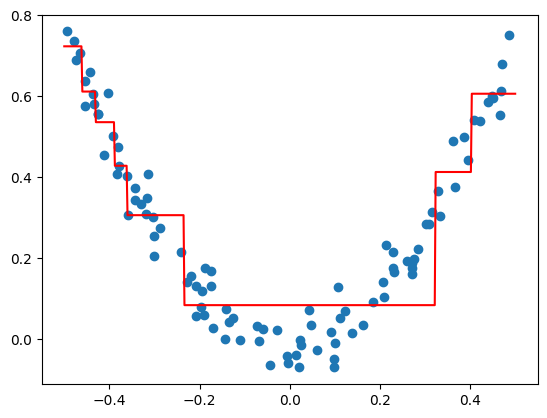

In [64]:
x_test = np.linspace(-0.5, 0.5, 500)
y_pred = 0.265458 + dt1.predict(x_test.reshape(500, 1))
plt.scatter(df['X'], df['y'])
plt.plot(x_test, y_pred, color = 'r')

In [55]:
df['r2'] = df['y'] - df['pred1']

In [57]:
df.head()

,X,y,pred0,r1,pred1,r2
0,-0.125460,0.051573,0.265458,-0.213885,0.083770,-0.032197
1,0.450714,0.594480,0.265458,0.329021,0.605884,-0.011404
2,0.231994,0.166052,0.265458,-0.099407,0.083770,0.082282
3,0.098658,-0.070178,0.265458,-0.335636,0.083770,-0.153948
4,-0.343981,0.343986,0.265458,0.078528,0.305965,0.038021


In [56]:
dt2 = DecisionTreeRegressor(max_depth= 3)

In [58]:
dt2.fit(X, df.iloc[:, -1])

,criterion,'squared_error'
,splitter,'best'
,max_depth,3
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [59]:
df['pred2'] = df['pred1'] + dt2.predict(X)

In [60]:
df.head()

,X,y,pred0,r1,pred1,r2,pred2
0,-0.125460,0.051573,0.265458,-0.213885,0.083770,-0.032197,-0.002159
1,0.450714,0.594480,0.265458,0.329021,0.605884,-0.011404,0.589162
2,0.231994,0.166052,0.265458,-0.099407,0.083770,0.082282,0.180857
3,0.098658,-0.070178,0.265458,-0.335636,0.083770,-0.153948,-0.002159
4,-0.343981,0.343986,0.265458,0.078528,0.305965,0.038021,0.310099


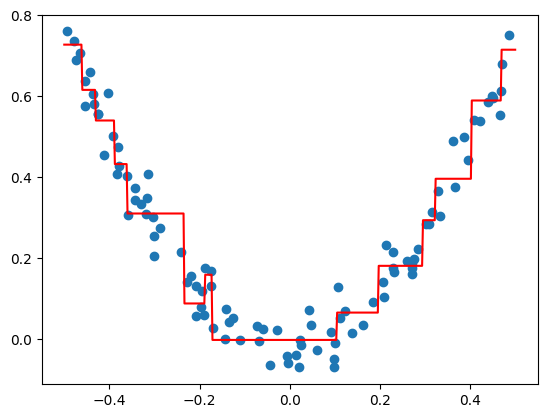

In [65]:
x_test = np.linspace(-0.5, 0.5, 500)
y_pred = 0.265458 + dt1.predict(x_test.reshape(500, 1)) + dt2.predict(x_test.reshape(500, 1))
plt.scatter(df['X'], df['y'])
plt.plot(x_test, y_pred, color = 'r')

In [87]:
def gradient_boost(X, y, m):
    
    if (m ==1):
        return np.ones(y.shape)* y.mean()
    else:
        y_hat = np.ones(y.shape)* y.mean()
        y_pred = y.mean()
        for i in range(1, m):
            r = y - y_hat
            dt = DecisionTreeRegressor(max_depth= 3)
            dt.fit(X, r)
            x_test = np.linspace(-0.5, 0.5, 500)
            y_pred = y_pred + dt.predict(x_test.reshape(500, 1))
            plt.figure()
            plt.scatter(X[:, 0], y)
            plt.plot(x_test, y_pred, color = 'r')
            y_hat = y_hat + dt.predict(X)

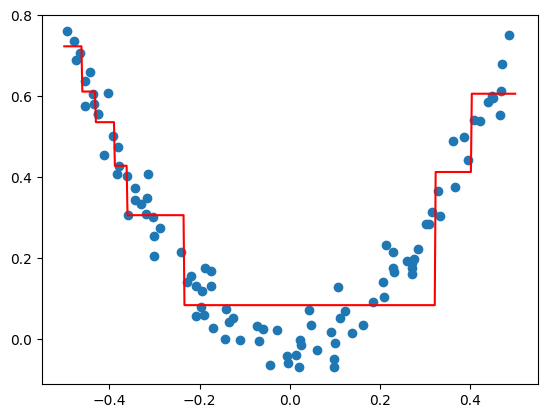

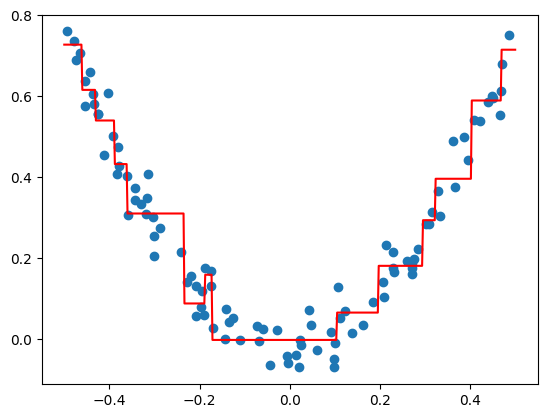

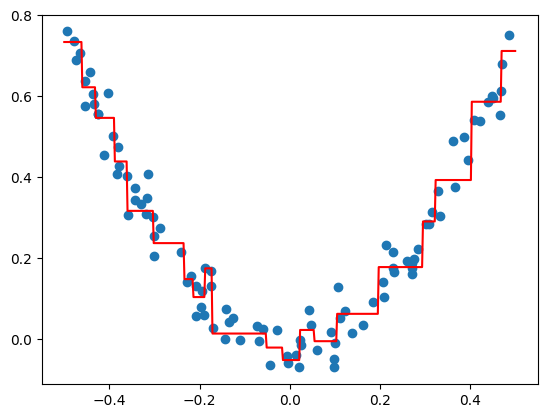

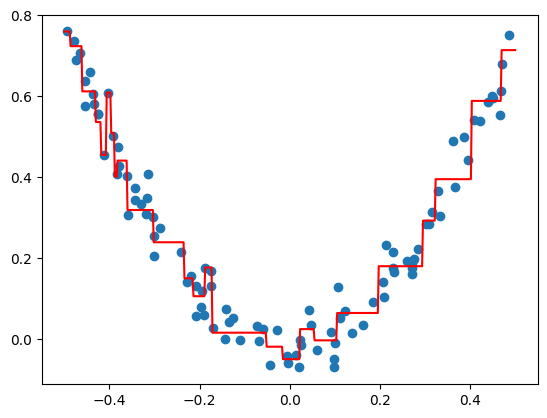

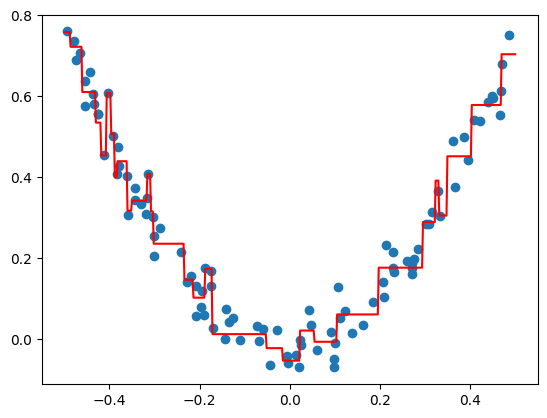

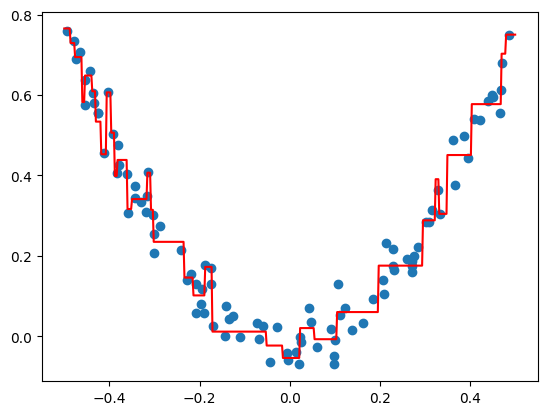

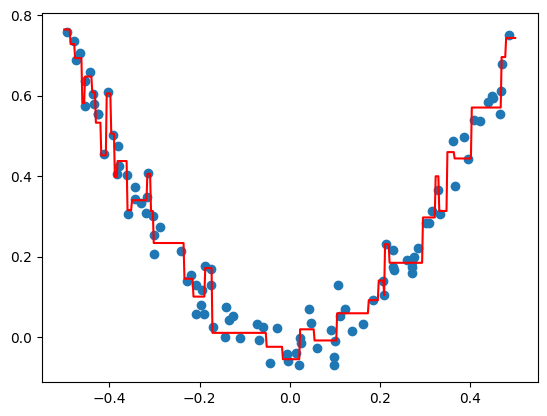

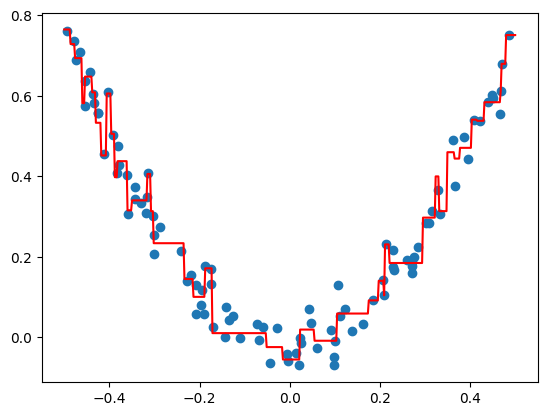

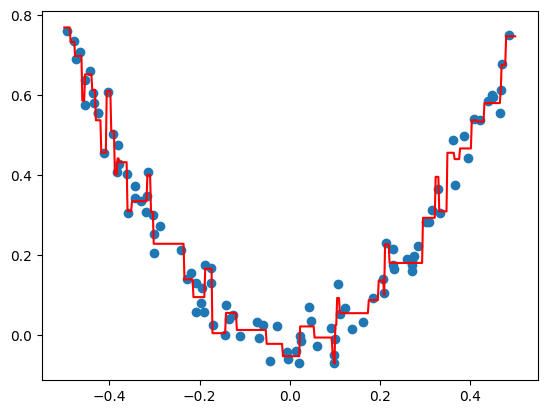

In [91]:
gradient_boost(X, y, 10)